In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [7]:

import pandas as pd

df = pd.read_csv(r"C:\Users\Poison\Downloads\Telegram Desktop\lab_ticket_resolution.csv")

print("Dataset loaded successfully!")
print("Dataset shape (rows, columns):", df.shape)

df.head()


Dataset loaded successfully!
Dataset shape (rows, columns): (240, 6)


,ticket_id,complexity_score,lines_changed,team_experience_years,reopened,resolution_hours
0,T0001,6,67,5.6,1,24.77
1,T0002,9,72,11.5,0,33.43
2,T0003,6,49,3.3,0,17.82
3,T0004,5,50,9.6,1,19.54
4,T0005,3,33,6.4,1,11.04


In [8]:

print("Dataset information:")
df.info()

print("\nMissing values in each column:")
print(df.isnull().sum())

print("\nSummary statistics:")
df.describe()


Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 240 entries, 0 to 239
Data columns (total 6 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   ticket_id              240 non-null    str    
 1   complexity_score       240 non-null    int64  
 2   lines_changed          240 non-null    int64  
 3   team_experience_years  240 non-null    float64
 4   reopened               240 non-null    int64  
 5   resolution_hours       240 non-null    float64
dtypes: float64(2), int64(3), str(1)
memory usage: 11.4 KB

Missing values in each column:
ticket_id                0
complexity_score         0
lines_changed            0
team_experience_years    0
reopened                 0
resolution_hours         0
dtype: int64

Summary statistics:


,complexity_score,lines_changed,team_experience_years,reopened,resolution_hours
count,240.000000,240.000000,240.000000,240.000000,240.000000
mean,5.491667,54.820833,6.105417,0.233333,19.361125
std,2.979697,26.145017,3.391426,0.423836,10.035058
min,1.000000,1.000000,0.500000,0.000000,0.500000
25%,3.000000,33.000000,3.300000,0.000000,11.015000
50%,5.500000,54.000000,5.800000,0.000000,19.610000
75%,8.000000,74.000000,9.200000,0.000000,27.122500
max,10.000000,113.000000,12.000000,1.000000,42.500000


In [9]:

print("Dataset information:")
df.info()

print("\nMissing values in each column:")
print(df.isnull().sum())

print("\nSummary statistics:")
df.describe()


Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 240 entries, 0 to 239
Data columns (total 6 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   ticket_id              240 non-null    str    
 1   complexity_score       240 non-null    int64  
 2   lines_changed          240 non-null    int64  
 3   team_experience_years  240 non-null    float64
 4   reopened               240 non-null    int64  
 5   resolution_hours       240 non-null    float64
dtypes: float64(2), int64(3), str(1)
memory usage: 11.4 KB

Missing values in each column:
ticket_id                0
complexity_score         0
lines_changed            0
team_experience_years    0
reopened                 0
resolution_hours         0
dtype: int64

Summary statistics:


,complexity_score,lines_changed,team_experience_years,reopened,resolution_hours
count,240.000000,240.000000,240.000000,240.000000,240.000000
mean,5.491667,54.820833,6.105417,0.233333,19.361125
std,2.979697,26.145017,3.391426,0.423836,10.035058
min,1.000000,1.000000,0.500000,0.000000,0.500000
25%,3.000000,33.000000,3.300000,0.000000,11.015000
50%,5.500000,54.000000,5.800000,0.000000,19.610000
75%,8.000000,74.000000,9.200000,0.000000,27.122500
max,10.000000,113.000000,12.000000,1.000000,42.500000


In [10]:

# Select the input features
X = df[[
    "complexity_score",
    "team_experience_years"
]]

# Select what we want to predict
y = df["resolution_hours"]

print("Features (X) shape:", X.shape)
print("Target (y) shape:", y.shape)

print("\nFirst five feature rows:")
print(X.head())

print("\nFirst five target values:")
print(y.head())


Features (X) shape: (240, 2)
Target (y) shape: (240,)

First five feature rows:
   complexity_score  team_experience_years
0                 6                    5.6
1                 9                   11.5
2                 6                    3.3
3                 5                    9.6
4                 3                    6.4

First five target values:
0    24.77
1    33.43
2    17.82
3    19.54
4    11.04
Name: resolution_hours, dtype: float64


In [11]:

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training targets:", y_train.shape)
print("Testing targets:", y_test.shape)


Training features: (192, 2)
Testing features: (48, 2)
Training targets: (192,)
Testing targets: (48,)


In [12]:

from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Create and train the baseline model
baseline = DummyRegressor(strategy="mean")
baseline.fit(X_train, y_train)

# Make predictions on the test data
y_pred_baseline = baseline.predict(X_test)

# Evaluate the baseline
mae = mean_absolute_error(y_test, y_pred_baseline)
rmse = np.sqrt(mean_squared_error(y_test, y_pred_baseline))
r2 = r2_score(y_test, y_pred_baseline)

print("Baseline Model Results")
print("----------------------")
print("MAE:", round(mae, 2))
print("RMSE:", round(rmse, 2))
print("R²:", round(r2, 3))


Baseline Model Results
----------------------
MAE: 9.11
RMSE: 10.6
R²: -0.021


In [13]:

from sklearn.linear_model import LinearRegression

# Create the model
linear_model = LinearRegression()

# Train it using the training data
linear_model.fit(X_train, y_train)

# Predict resolution time for the test data
y_pred_linear = linear_model.predict(X_test)

# Evaluate the model
mae_linear = mean_absolute_error(y_test, y_pred_linear)
rmse_linear = np.sqrt(mean_squared_error(y_test, y_pred_linear))
r2_linear = r2_score(y_test, y_pred_linear)

print("Linear Regression Results")
print("-------------------------")
print("MAE:", round(mae_linear, 2))
print("RMSE:", round(rmse_linear, 2))
print("R²:", round(r2_linear, 3))


Linear Regression Results
-------------------------
MAE: 2.91
RMSE: 3.57
R²: 0.884


In [14]:

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import LinearRegression

# Create a pipeline for polynomial regression
poly_pipeline = make_pipeline(
    PolynomialFeatures(include_bias=False),
    LinearRegression()
)

# Try polynomial degrees 2 and 3
param_grid = {
    "polynomialfeatures__degree": [2, 3]
}

poly_search = GridSearchCV(
    poly_pipeline,
    param_grid,
    cv=5,
    scoring="neg_mean_absolute_error"
)

# Choose the best degree using training data only
poly_search.fit(X_train, y_train)

print("Best polynomial degree:", poly_search.best_params_["polynomialfeatures__degree"])
print("Best cross-validation MAE:", round(-poly_search.best_score_, 2))

# Evaluate the selected model on the test set
y_pred_poly = poly_search.predict(X_test)

print("\nPolynomial Regression Results")
print("MAE:", round(mean_absolute_error(y_test, y_pred_poly), 2))
print("RMSE:", round(np.sqrt(mean_squared_error(y_test, y_pred_poly)), 2))
print("R²:", round(r2_score(y_test, y_pred_poly), 3))


Best polynomial degree: 3
Best cross-validation MAE: 3.13

Polynomial Regression Results
MAE: 3.14
RMSE: 3.95
R²: 0.858


In [15]:

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge, Lasso
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV

# Candidate alpha values
alpha_values = [0.01, 0.1, 1, 10, 100]

# Ridge Regression
ridge_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", Ridge())
])

ridge_search = GridSearchCV(
    ridge_pipeline,
    {"model__alpha": alpha_values},
    cv=5,
    scoring="neg_mean_absolute_error"
)

ridge_search.fit(X_train, y_train)
y_pred_ridge = ridge_search.predict(X_test)

print("Ridge Regression")
print("Best alpha:", ridge_search.best_params_["model__alpha"])
print("CV MAE:", round(-ridge_search.best_score_, 2))
print("Test MAE:", round(mean_absolute_error(y_test, y_pred_ridge), 2))
print("Test RMSE:", round(np.sqrt(mean_squared_error(y_test, y_pred_ridge)), 2))
print("Test R²:", round(r2_score(y_test, y_pred_ridge), 3))

# Lasso Regression
lasso_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", Lasso(max_iter=10000))
])

lasso_search = GridSearchCV(
    lasso_pipeline,
    {"model__alpha": alpha_values},
    cv=5,
    scoring="neg_mean_absolute_error"
)

lasso_search.fit(X_train, y_train)
y_pred_lasso = lasso_search.predict(X_test)

print("\nLasso Regression")
print("Best alpha:", lasso_search.best_params_["model__alpha"])
print("CV MAE:", round(-lasso_search.best_score_, 2))
print("Test MAE:", round(mean_absolute_error(y_test, y_pred_lasso), 2))
print("Test RMSE:", round(np.sqrt(mean_squared_error(y_test, y_pred_lasso)), 2))
print("Test R²:", round(r2_score(y_test, y_pred_lasso), 3))


Ridge Regression
Best alpha: 1
CV MAE: 3.21
Test MAE: 2.91
Test RMSE: 3.57
Test R²: 0.884

Lasso Regression
Best alpha: 0.01
CV MAE: 3.21
Test MAE: 2.91
Test RMSE: 3.57
Test R²: 0.884


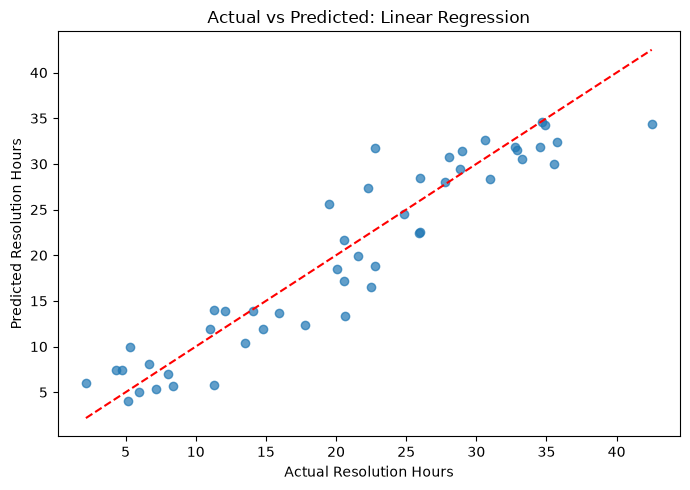

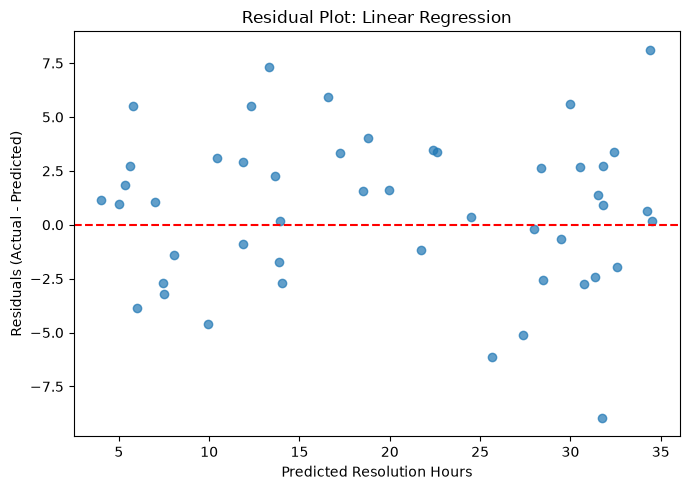

In [16]:

# Plot 1: Actual (observed) vs predicted values
plt.figure(figsize=(7, 5))

plt.scatter(y_test, y_pred_linear, alpha=0.7)

# Reference line: perfect predictions
min_value = min(y_test.min(), y_pred_linear.min())
max_value = max(y_test.max(), y_pred_linear.max())
plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    "r--"
)

plt.xlabel("Actual Resolution Hours")
plt.ylabel("Predicted Resolution Hours")
plt.title("Actual vs Predicted: Linear Regression")
plt.tight_layout()
plt.show()


# Plot 2: Residuals
residuals = y_test - y_pred_linear

plt.figure(figsize=(7, 5))
plt.scatter(y_pred_linear, residuals, alpha=0.7)
plt.axhline(y=0, color="red", linestyle="--")

plt.xlabel("Predicted Resolution Hours")
plt.ylabel("Residuals (Actual - Predicted)")
plt.title("Residual Plot: Linear Regression")
plt.tight_layout()
plt.show()


 Model Evaluation and Analysis

1. Why is a mean baseline useful?
The mean baseline provides a simple reference point. It predicts the average resolution time from the training data for every ticket. More advanced models should outperform this baseline to demonstrate that they have learned useful relationships.

2. Which model has the lowest MAE and RMSE?
Linear Regression, Ridge Regression, and Lasso Regression have the same reported test MAE of 2.91 hours and RMSE of 3.57 hours. They also have the same reported R² of 0.884. These values are tied at the displayed precision.

3. Did Polynomial Regression improve performance?
No. Polynomial Regression selected degree 3 through cross-validation, but its test MAE (3.14) and RMSE (3.95) were higher than Linear Regression's. Its R² was also lower (0.858 compared with 0.884). The additional polynomial features did not improve test performance.

4. How did regularization affect performance?
Ridge and Lasso produced the same reported test metrics as Linear Regression. In this experiment, regularization did not provide a measurable improvement at the displayed precision. The selected alpha values were 1 for Ridge and 0.01 for Lasso.

5. Why is feature scaling important for Ridge and Lasso?
Feature scaling puts numerical features on comparable scales. This matters because Ridge and Lasso penalize coefficient sizes, and features measured on different scales can otherwise be affected differently by the penalty.

6. What is data leakage, and how could it affect this task?
Data leakage occurs when a model uses information that would not legitimately be available at prediction time. For example, `lines_changed` or `reopened` could cause leakage if those values are only known after a ticket is resolved. Features should be selected based on what is available when predictions are made.

7. Is a random train/test split always appropriate?
No. A random split may be unsuitable when the goal is to predict future tickets, when multiple records belong to the same customer, or when teams and time periods create dependencies. A time-based split or group-based split may provide a more realistic evaluation in those cases.

8. What additional checks are needed before deployment?
Before deployment, the model should be tested on representative future data, checked for data leakage and unusual errors, and monitored for changes in ticket patterns. Prediction accuracy, data quality, and the consequences of inaccurate estimates should also be considered.


In [17]:

results = pd.DataFrame({
    "Model": [
        "Baseline",
        "Linear Regression",
        "Polynomial Regression",
        "Ridge Regression",
        "Lasso Regression"
    ],
    "MAE": [
        mean_absolute_error(y_test, y_pred_baseline),
        mean_absolute_error(y_test, y_pred_linear),
        mean_absolute_error(y_test, y_pred_poly),
        mean_absolute_error(y_test, y_pred_ridge),
        mean_absolute_error(y_test, y_pred_lasso)
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(y_test, y_pred_baseline)),
        np.sqrt(mean_squared_error(y_test, y_pred_linear)),
        np.sqrt(mean_squared_error(y_test, y_pred_poly)),
        np.sqrt(mean_squared_error(y_test, y_pred_ridge)),
        np.sqrt(mean_squared_error(y_test, y_pred_lasso))
    ],
    "R2": [
        r2_score(y_test, y_pred_baseline),
        r2_score(y_test, y_pred_linear),
        r2_score(y_test, y_pred_poly),
        r2_score(y_test, y_pred_ridge),
        r2_score(y_test, y_pred_lasso)
    ]
})

results.round(3)


,Model,MAE,RMSE,R2
0,Baseline,9.114,10.598,-0.021
1,Linear Regression,2.906,3.572,0.884
2,Polynomial Regression,3.140,3.949,0.858
3,Ridge Regression,2.905,3.571,0.884
4,Lasso Regression,2.907,3.572,0.884


Final Recommendation

Based on the test results, I recommend Linear Regression as the preferred model for this experiment. It achieved a test MAE of 2.91 hours, RMSE of 3.57 hours, and R² of 0.884. Ridge and Lasso achieved the same reported metrics, while Polynomial Regression performed slightly worse.

Linear Regression is a reasonable choice because it provides good predictive performance without adding unnecessary polynomial complexity.

Limitations

- Only two features, `complexity_score` and `team_experience_years`, were used.
- The dataset is synthetic, so these results may not represent real support tickets.
- The test set is relatively limited and may not represent future tickets.
- Some relevant factors, such as ticket category, priority, and workload, were not included.
- The model should be tested on real, future ticket data before being used in practice.
- The model's predictions are estimates and should not be treated as guaranteed resolution times.